# Rewriting a RAMSES output for any number of CPUs

A production galaxy simulation, written by RAMSES on 5120 MPI ranks, rewritten for 512, 5120 and
10240 ranks, once from its RAMSES files and once from its Mera file alone. Every value is checked,
and the cost is measured: time, memory and disk space, for writing and for reading back.

![The same snapshot split for 512, 5120 and 10240 ranks](media/ramses_any_rank_count_thumb.png)

| | |
|---|---|
| **Author** | Manuel Behrendt, MPE Garching |
| **Contact** | github.com/ManuelBehrendt |
| **Reads** | RAMSES |
| **Mera** | 1.8.0 (dev transfer-functions @ f4f5480), Julia 1.13.1 |
| **Provenance** | `Mera v1.8.0 (dev transfer-functions @ f4f5480) | L13_SN5_CD_null/output_00201 | 296.74 Myr | L=48.0 ndim=3 lmin=6 lmax=13 | ScalesType003` |
| **Status** | contributed 2026-10-06 |

RAMSES restarts a run only with the number of ranks that wrote it. [`repartition`](https://manuelbehrendt.github.io/Mera.jl/stable/api/ramses_writer/)
rewrites an output for any other number, and [`writeramses`](https://manuelbehrendt.github.io/Mera.jl/stable/api/ramses_writer/)
writes one from Mera data, for example from a mera file when the RAMSES files are gone. How they
work, and the checks against RAMSES itself (restarts to round-off for every kind of run), are on the
page [Restart RAMSES with any number of CPUs](https://manuelbehrendt.github.io/Mera.jl/stable/07_2_multi_RAMSES_Restart/).
This recipe is the same on a large run: 28 million grids, 197 million leaf cells and 410 000
particles in a 58 GB output.

**It needs Mera 1.8**, the first release with the RAMSES writer. **Cost**: on a server with 16 threads, a few hours for everything, about 80 GB of memory at
most, and about 400 GB of free disk for the six rewritten outputs (deleted at the end if you wish).
Try it first on a small output, or on one of the public test simulations from `download_testdata()`.

## The environment

This recipe carries its own `Project.toml`. The cell below uses exactly the package versions it was
written against, whatever else you have installed. See
[Reproducibility](https://manuelbehrendt.github.io/Mera.jl/stable/reproducibility/).

In [1]:
using Pkg
Pkg.activate(@__DIR__)        # the Project.toml next to this notebook
Pkg.instantiate()             # first run only: fetches those versions

  Activating 

project at `~/julia/gallery/005_ramses_any_rank_count`


## What you change

The RAMSES output, its mera file, a folder with room for the rewritten outputs, and the rank counts.

In [2]:
using Mera, CairoMakie, Printf, Dates, Random

# ---- the reader changes these ---------------------------------------------------------
const SIM       = "/data1/mabe/Simulations/MilkyWay/RAMSESFiles/heikou/L13_SN5_CD_null"  # RAMSES run
const OUTPUT    = 201
const MERAFILES = "/data1/mabe/Simulations/MilkyWay/JLD2Files/heikou/L13_SN_CD_null"     # its mera file
const WORK      = "/data1/mabe/Simulations/MilkyWay/RAMSESFiles/heikou/rewrite_tests_201" # scratch
const RANKS     = [512, 5120, 10240]
# ---------------------------------------------------------------------------------------

const RW = Mera.RamsesWriter      # the file-format machinery, used here only to look inside
mkpath(WORK); mkpath(joinpath(@__DIR__, "media"))
info = getinfo(OUTPUT, SIM, verbose=false)
println("ncpu = ", info.ncpu, ", levels ", info.levelmin, " to ", info.levelmax,
        ", time ", round(gettime(info, :Myr), digits=1), " Myr")


*__   __ _______ ______   _______ 


|  |_|  |       |    _ | |   _   |
|       |    ___|   | || |  |_|  |
|       |   |___|   |_||_|       |
|       |    ___|    __  |       |
| ||_|| |   |___|   |  | |   _   |
|_|   |_|_______|___|  |_|__| |__|
Mera v1.8.0 | Julia 1.13.1 | 16 threads

ncpu = 

5120, levels 6 to 13, time 296.7 Myr


## Attribution: run this once and paste the result

In [3]:
AUTHOR  = "Manuel Behrendt, MPE Garching"
CONTACT = "github.com/ManuelBehrendt"
L0 = loaddata(OUTPUT, MERAFILES, :hydro; verbose=false)      # also the provenance of what was read
println("""
| | |
|---|---|
| **Author** | $AUTHOR |
| **Contact** | $CONTACT |
| **Reads** | $(info.simcode) |
| **Mera** | $(mera_build()), Julia $(VERSION) |
| **Provenance** | `$(provenance_string(L0))` |
| **Status** | contributed $(Dates.today()) |
""")
L0 = nothing; GC.gc()

| | |
|---|---|
| **Author** | Manuel Behrendt, MPE Garching |
| **Contact** | github.com/ManuelBehrendt |
| **Reads** | RAMSES |
| **Mera** | 1.8.0 (dev transfer-functions @ 086dd0c), Julia 1.13.1 |
| **Provenance** | `Mera v1.8.0 (dev transfer-functions @ 086dd0c) | L13_SN5_CD_null/output_00201 | 296.74 Myr | L=48.0 ndim=3 lmin=6 lmax=13 | ScalesType003` |
| **Status** | contributed 2026-10-07 |



## The recipe

### 1. Measuring cost honestly

Every step below is timed, and its memory is followed while it runs. On Linux the useful number is
the **anonymous** resident memory (`RssAnon`): the converter maps the old files into memory, and the
operating system counts those pages as resident although it can drop them at any time. A helper
samples `RssAnon` twice a second and keeps the largest value. The disk size and the number of files
of every output are recorded too.

In [4]:
# Linux: anonymous resident memory. Elsewhere (macOS) the process's largest resident size, which
# includes the mapped file pages, so it overstates the cost of `repartition`.
rss_anon() = isfile("/proc/self/status") ?
    open("/proc/self/status") do io
        for l in eachline(io)
            startswith(l, "RssAnon:") && return parse(Int, split(l)[2]) / 2^20    # kB -> GB
        end
        NaN
    end : Sys.maxrss() / 2^30

"Runs f(), returns (result, seconds, largest RssAnon in GB while it ran)."
function measure(f)
    GC.gc(); GC.gc()
    peak = Ref(rss_anon()); running = Ref(true)
    # on the interactive thread (Julia 1.12 and later always start one): a sampler on the worker
    # threads would get no turn while every one of them is busy, and miss the peak
    sampler = Threads.@spawn :interactive while running[]
        peak[] = max(peak[], rss_anon()); sleep(0.2)
    end
    t = @elapsed r = f()
    running[] = false; wait(sampler)
    return r, t, max(peak[], rss_anon())
end

dirsize(d) = sum((filesize(joinpath(r, f)) for (r, _, fs) in walkdir(d) for f in fs); init=0) / 2^30
nfiles(d)  = sum((length(fs) for (_, _, fs) in walkdir(d)); init=0)
outdir(path) = joinpath(path, "output_" * lpad(OUTPUT, 5, '0'))

results = NamedTuple[]
record!(; kw...) = (push!(results, NamedTuple(kw)); kw)
orig = outdir(SIM)
@printf("original: %.1f GB in %d files, %d ranks\n", dirsize(orig), nfiles(orig), info.ncpu)

original: 57.8 GB in 20489 files, 5120 ranks


### 2. From the RAMSES files: `repartition`

`repartition` reads the octree of all old files, cuts the Hilbert curve into the new number of
domains, builds every new rank's octree as RAMSES would hold it in memory, and copies the values bit
for bit. It keeps the octree in memory once and never loads the values: they are read block by block
from the old files while the new ones are written. Even at the same rank count the walls are new:
balanced on cells and particles, where RAMSES's own walls come from its last load balance.

In [5]:
for n in RANKS
    out = joinpath(WORK, "repartition_$n")
    rep, t, peak = measure(() -> repartition(OUTPUT, SIM, n; outpath=out, overwrite=true, verbose=false))
    record!(route="repartition", ranks=n, seconds=t, peak_gb=peak, size_gb=dirsize(outdir(out)),
            files=nfiles(outdir(out)), ngridmax=rep.ngridmax_needed)
    @printf("repartition to %5d ranks: %6.0f s, peak %5.1f GB, %6.1f GB in %6d files, ngridmax %d\n",
            n, t, peak, results[end].size_gb, results[end].files, rep.ngridmax_needed)
end

repartition to   512 ranks:     87 s, peak   7.4 GB,   29.6 GB in   2057 files, ngridmax 82164


repartition to  5120 ranks:    268 s, peak   8.8 GB,   58.1 GB in  20489 files, ngridmax 11606


repartition to 10240 ranks:    790 s, peak  10.5 GB,  122.8 GB in  40969 files, ngridmax 6891


### 3. From the mera file alone: `writeramses`

A mera file keeps the leaf cells with all their variables, the particles, and here the gravity of the
refined cells (`getgravity(info; parents=true)` when the file was made). `writeramses` rebuilds the
whole octree from the leaves, the refined hydro cells as RAMSES builds them, and writes the same
kind of output. Unlike `repartition` it holds all cells in memory, so its memory grows with the data.

In [6]:
L, t, peak = measure() do
    (hydro     = loaddata(OUTPUT, MERAFILES, :hydro;     verbose=false),
     gravity   = loaddata(OUTPUT, MERAFILES, :gravity;   verbose=false),
     particles = loaddata(OUTPUT, MERAFILES, :particles; verbose=false))
end
mf = joinpath(MERAFILES, "output_" * lpad(OUTPUT, 5, '0') * ".jld2")
record!(route="load mera file", ranks=0, seconds=t, peak_gb=peak, size_gb=filesize(mf) / 2^30, files=1, ngridmax=0)
@printf("mera file: %.1f GB, loaded in %.0f s, %.1f GB in memory; %d leaf cells, %d particles\n",
        filesize(mf) / 2^30, t, peak, length(L.hydro.data), length(L.particles.data))
@printf("complete for a restart: %s\n", first(restart_completeness(L.hydro; gravity=L.gravity, particles=L.particles)))

for n in RANKS
    out = joinpath(WORK, "writeramses_$n")
    rep, t, peak = measure(() -> writeramses(n; L..., outpath=out, overwrite=true, verbose=false))
    record!(route="writeramses", ranks=n, seconds=t, peak_gb=peak, size_gb=dirsize(outdir(out)),
            files=nfiles(outdir(out)), ngridmax=rep.ngridmax_needed)
    @printf("writeramses to %5d ranks: %6.0f s, peak %5.1f GB (with the loaded data), %6.1f GB in %6d files\n",
            n, t, peak, results[end].size_gb, results[end].files)
end
L = nothing; GC.gc()

mera file: 15.9 GB, loaded in 79 s, 33.5 GB in memory; 197106526 leaf cells, 410342 particles


complete for a restart: true


writeramses to   512 ranks:    281 s, peak  67.1 GB (with the loaded data),   29.6 GB in   2057 files


writeramses to  5120 ranks:    456 s, peak  72.2 GB (with the loaded data),   58.1 GB in  20489 files


writeramses to 10240 ranks:    899 s, peak  73.2 GB (with the loaded data),  122.8 GB in  40969 files


### 4. Every value, compared

[`compareramses`](https://manuelbehrendt.github.io/Mera.jl/stable/api/ramses_writer/) matches every
grid by its position and every particle by its identity, so a different grid numbering or rank
order is not a difference. Differences are relative to each variable's largest value. From the
RAMSES files every value is copied, so everything must be exactly zero. From the mera file the leaf
cells and particles are copied (zero), and the refined hydro cells are rebuilt from their children,
so they carry round-off.

In [7]:
cmp = NamedTuple[]
for route in ("repartition", "writeramses"), n in RANKS
    c, t, _ = measure(() -> compareramses(OUTPUT, SIM, joinpath(WORK, "$(route)_$n")))
    worst(k) = haskey(c.maxdiff, k) ? maximum(c.maxdiff[k]) : NaN
    push!(cmp, (route=route, ranks=n, same_tree=c.same_tree, hydro=worst("hydro"), grav=worst("grav"),
                particles=c.particle_maxdiff[1], nparticles=c.nparticles))
    @printf("%-12s %5d ranks: octree %s  hydro %.0e  gravity %.0e  particles %.0e (%d of %d)  [%.0f s]\n",
            route, n, c.same_tree ? "same" : "DIFFERENT", cmp[end].hydro, cmp[end].grav, cmp[end].particles,
            c.nparticles[2], c.nparticles[1], t)
end

repartition    512 ranks: octree same  hydro 0e+00  gravity 0e+00  particles 0e+00 (410342 of 410342)  [546 s]


repartition   5120 ranks: octree same  hydro 0e+00  gravity 0e+00  particles 0e+00 (410342 of 410342)  [362 s]


repartition  10240 ranks: octree same  hydro 0e+00  gravity 0e+00  particles 0e+00 (410342 of 410342)  [881 s]


writeramses    512 ranks: octree same  hydro 3e-16  gravity 0e+00  particles 0e+00 (410342 of 410342)  [408 s]


writeramses   5120 ranks: octree same  hydro 3e-16  gravity 0e+00  particles 0e+00 (410342 of 410342)  [420 s]


writeramses  10240 ranks: octree same  hydro 3e-16  gravity 0e+00  particles 0e+00 (410342 of 410342)  [804 s]


The two routes can also be compared with each other at the same rank count: the output rewritten
from the RAMSES files against the one written from the mera file. They have the same octree, the
same leaf cells and the same particles, so the only differences left are the rebuilt refined cells.

In [8]:
pair = NamedTuple[]
for n in RANKS
    c = compareramses(OUTPUT, joinpath(WORK, "repartition_$n"), joinpath(WORK, "writeramses_$n"))
    worst(k) = haskey(c.maxdiff, k) ? maximum(c.maxdiff[k]) : NaN
    leaves = compareramses(OUTPUT, joinpath(WORK, "repartition_$n"), joinpath(WORK, "writeramses_$n"); leaves_only=true)
    push!(pair, (ranks=n, same_tree=c.same_tree, hydro=worst("hydro"), grav=worst("grav"),
                 hydro_leaves=maximum(leaves.maxdiff["hydro"]), particles=c.particle_maxdiff[1]))
    @printf("%5d ranks, RAMSES files vs mera file: octree %s  hydro %.0e (leaf cells %.0e)  gravity %.0e  particles %.0e\n",
            n, c.same_tree ? "same" : "DIFFERENT", pair[end].hydro, pair[end].hydro_leaves, pair[end].grav, pair[end].particles)
end
open(joinpath(@__DIR__, "media", "compare_routes.csv"), "w") do io
    println(io, "ranks,same_tree,hydro,hydro_leaves,grav,particles")
    foreach(r -> println(io, join(values(r), ',')), pair)
end

  512 ranks, RAMSES files vs mera file: octree same  hydro 3e-16 (leaf cells 0e+00)  gravity 0e+00  particles 0e+00


 5120 ranks, RAMSES files vs mera file: octree same  hydro 3e-16 (leaf cells 0e+00)  gravity 0e+00  particles 0e+00


10240 ranks, RAMSES files vs mera file: octree same  hydro 3e-16 (leaf cells 0e+00)  gravity 0e+00  particles 0e+00


### 5. Where the ranks are

Each rank owns a stretch of the Hilbert curve, about the same number of cells each. In a slice
through the disc's midplane the domains are small where the cells are fine and large in the halo.
The colours are random per rank, so neighbouring domains differ.

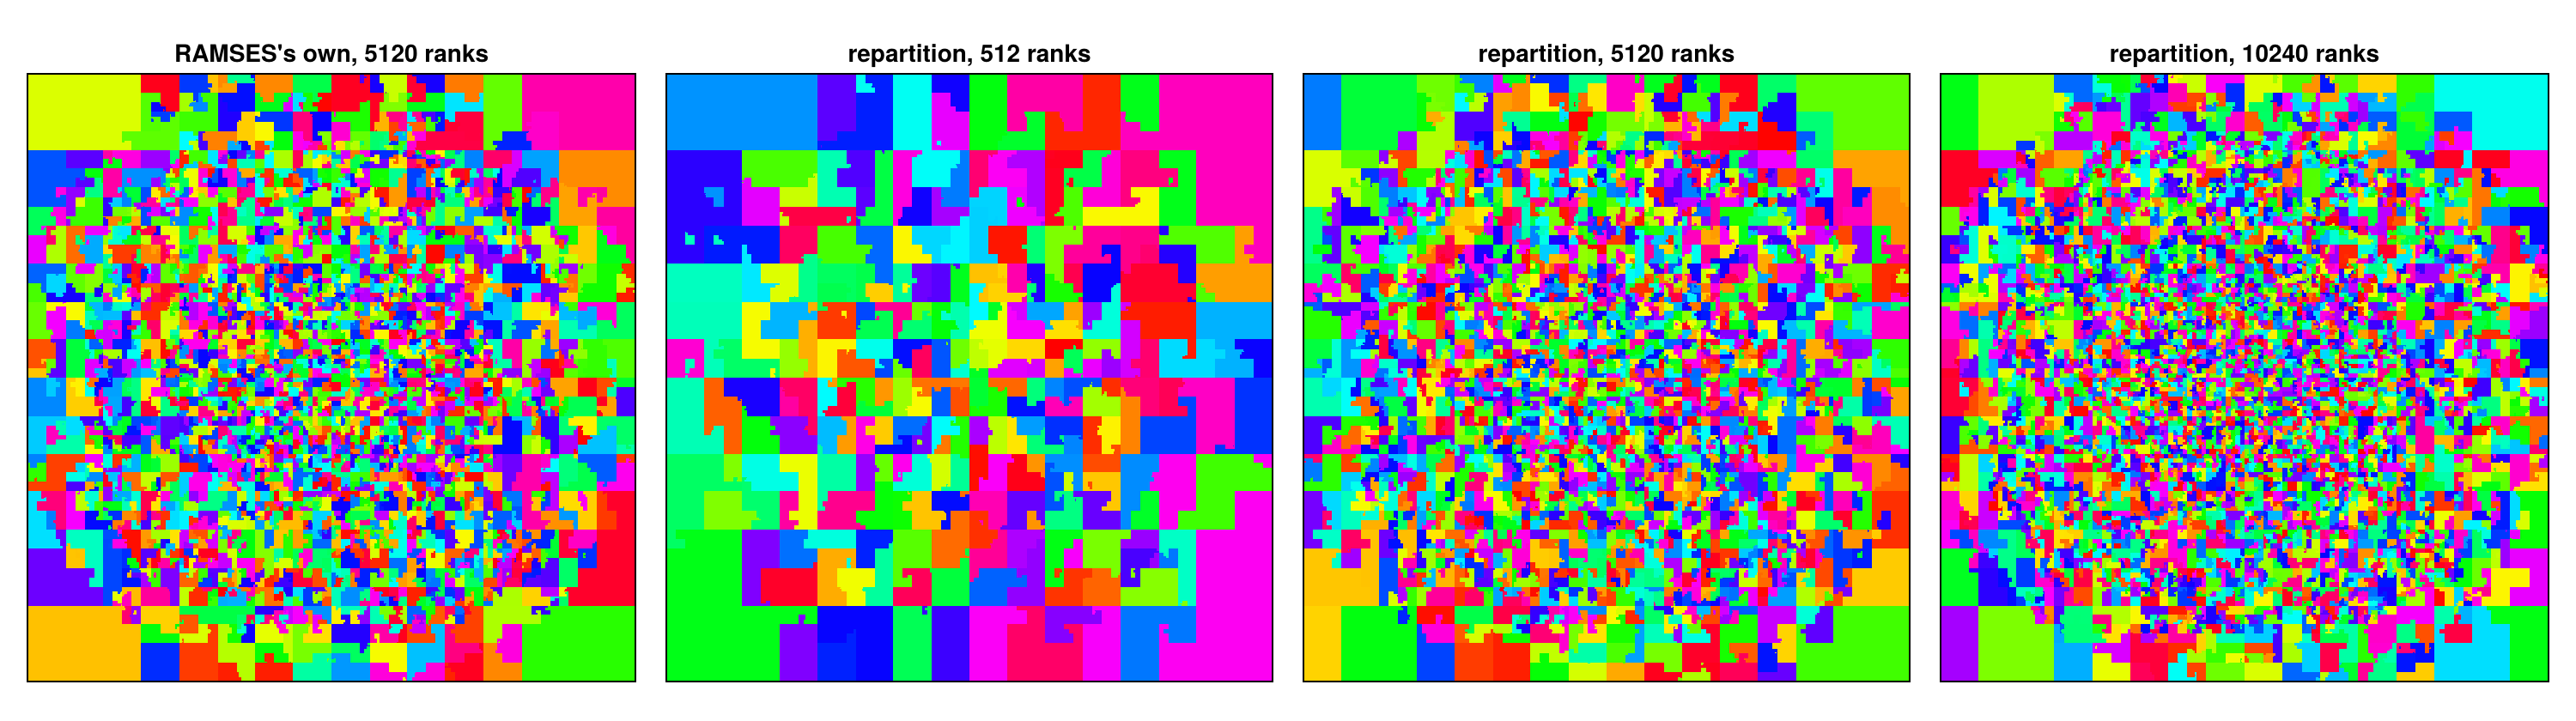

In [9]:
# The value of the cell under each pixel of an n×n slice through `pos` (box units) along `axis`,
# over the part [lo, hi] of the box. With `lmax` the cell is taken at that level at most, so a
# refined (parent) cell shows instead of its children.
function slice_map(t, value; pos=0.5, axis=3, n=700, lo=0.25, hi=0.75, lmax=typemax(Int))
    img = fill(NaN, n, n)
    Threads.@threads for i in 1:n
        for j in 1:n
            u, v = lo + (i - 0.5) / n * (hi - lo), lo + (j - 0.5) / n * (hi - lo)
            x = axis == 3 ? (u, v, pos) : axis == 2 ? (u, pos, v) : (pos, u, v)
            xc = x .* t.geom.nx_loc .+ t.geom.cmin                      # coarse-cell units
            g = RW.find_grid(t, 1, RW.Coord(floor.(Int32, xc))); g == 0 && continue
            l = 1
            while true
                c = ntuple(d -> floor(Int, xc[d] * 2^l), 3)
                child = l < lmax ? RW.find_grid(t, l + 1, RW.Coord(c)) : 0
                if child == 0
                    img[i, j] = value(l, g, RW.cell_index((c .& 1)...)); break
                end
                g, l = child, l + 1
            end
        end
    end
    img
end

tree(dir) = RW.read_global_tree(dir, OUTPUT; verbose=false)
owner_map(dir; kw...) = (t = tree(dir); dec = RW.own_decomposition(t);
                         slice_map(t, (l, g, ind) -> dec.cpu_map[l][g, ind]; kw...))

shuffle_colors(img) = (p = randperm(MersenneTwister(1), Int(maximum(filter(!isnan, img))));
                       map(v -> isnan(v) ? NaN : Float64(p[Int(v)]), img))
maps = [("RAMSES's own, $(info.ncpu) ranks", owner_map(orig));
        [("repartition, $n ranks", owner_map(outdir(joinpath(WORK, "repartition_$n")))) for n in RANKS]]
fig = Figure(size=(1500, 420))
for (k, (title, img)) in enumerate(maps)
    ax = Axis(fig[1, k]; title, aspect=DataAspect()); hidedecorations!(ax)
    heatmap!(ax, shuffle_colors(img); colormap=:hsv)
end
save(joinpath(@__DIR__, "media", "domains.png"), fig); fig

### 6. Every cell, counted

`compareramses` above gives the largest difference of each variable. Here every cell is counted: how
many are exactly equal, and how the remaining differences are spread. Leaf cells and refined cells
are counted apart, because the routes treat them differently: `repartition` copies both, `writeramses`
copies the leaves and rebuilds the refined cells from their children. The rank count makes no
difference (the two routes compared at 512, 5120 and 10240 ranks above give the same numbers), so the
512-rank outputs stand for all three.

repartition, 512 ranks: 197106526 leaf cells, 28158074 refined cells
  rho    leaf cells equal   197106526 of 197106526   refined cells equal   28158074 of 28158074   largest difference 0e+00


  vx     leaf cells equal   197106526 of 197106526   refined cells equal   28158074 of 28158074   largest difference 0e+00
  vy     leaf cells equal   197106526 of 197106526   refined cells equal   28158074 of 28158074   largest difference 0e+00
  vz     leaf cells equal   197106526 of 197106526   refined cells equal   28158074 of 28158074   largest difference 0e+00
  p      leaf cells equal   197106526 of 197106526   refined cells equal   28158074 of 28158074   largest difference 0e+00
  scalar_00 leaf cells equal   197106526 of 197106526   refined cells equal   28158074 of 28158074   largest difference 0e+00
  scalar_01 leaf cells equal   197106526 of 197106526   refined cells equal   28158074 of 28158074   largest difference 0e+00
writeramses, 512 ranks: 197106526 leaf cells, 28158074 refined cells
  rho    leaf cells equal   197106526 of 197106526   refined cells equal   28142777 of 28158074   largest difference 1e-19
  vx     leaf cells equal   197106526 of 197106526   refined cel

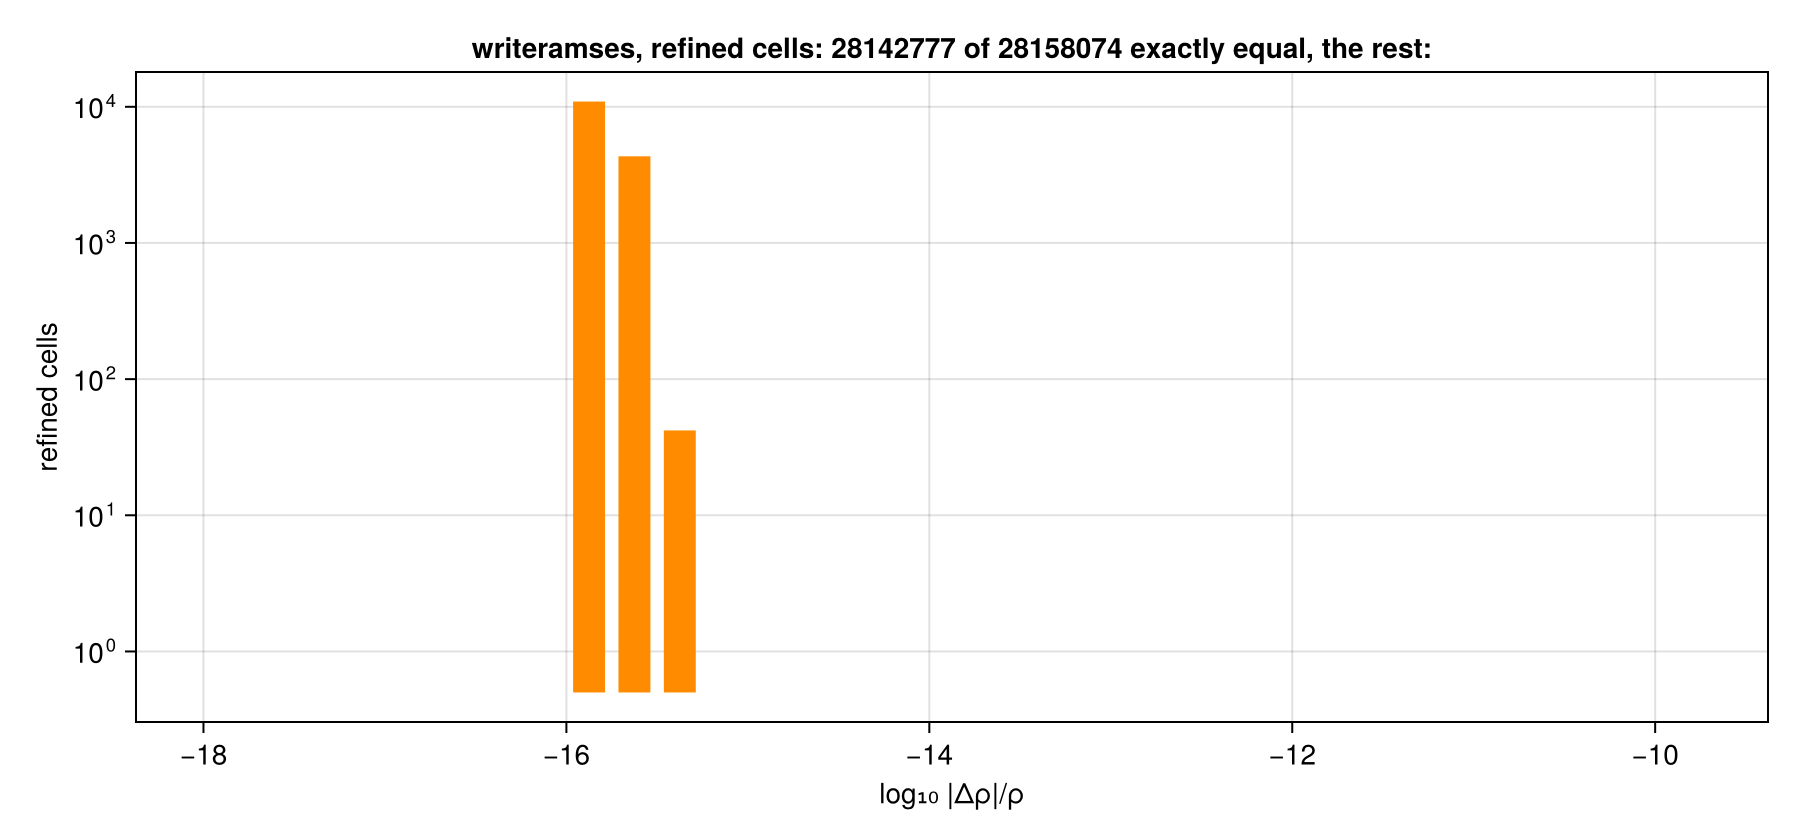

In [10]:
"""
Every cell of output `b` against output `a`, matched by position (the octrees are the same, as
compared above). For every hydro variable: how many cells are exactly equal, and the largest
difference relative to the variable's largest value. For the density also the distribution of
|Δρ|/ρ, for leaf cells and refined cells apart.
"""
function cell_differences(a, b; edges = 10.0 .^ (-18:0.25:-10))
    ta, tb = tree(a), tree(b)
    opencs(d, t) = RW.open_cell_files(d, "hydro", OUTPUT, Int(t.header.ncpu), Int(t.header.nlevelmax),
                                      length(t.boundaries); lists=t.lists)
    ca, cb = opencs(a, ta), opencs(b, tb)
    nv = ca.nvar
    jobs = [(l, r) for l in 1:RW.nlevels(ta) for r in Iterators.partition(1:RW.ngrids(ta.levels[l]), 1 << 14)]
    tasks = map(Iterators.partition(jobs, cld(length(jobs), Threads.nthreads()))) do part
        Threads.@spawn begin
            ncell = zeros(Int, 2); equal = zeros(Int, 2, nv); maxd = zeros(nv); vmax = zeros(nv)
            hist = zeros(Int, 2, length(edges) + 1)        # row 1 leaf, row 2 refined; column 1 exactly zero
            for (l, r) in part, g in r
                ig = ta.levels[l].ig[g]; h = tb.levels[l].lookup[ig]
                ka, pa = ta.src_cpu[l][g], ta.src_pos[l][g]
                kb, pb = tb.src_cpu[l][h], tb.src_pos[l][h]
                for ind in 1:8
                    kind = RW.is_refined(ta, l, ig, ind) ? 2 : 1
                    ncell[kind] += 1
                    for v in 1:nv
                        x = RW.cell_value(ca, ka, l, ka, pa, ind, v)
                        y = RW.cell_value(cb, kb, l, kb, pb, ind, v)
                        x == y && (equal[kind, v] += 1)
                        maxd[v] = max(maxd[v], abs(x - y)); vmax[v] = max(vmax[v], abs(x))
                        if v == 1
                            rel = abs(x - y) / abs(x)
                            hist[kind, rel == 0 ? 1 : 1 + clamp(searchsortedlast(edges, rel), 1, length(edges))] += 1
                        end
                    end
                end
            end
            (ncell, equal, maxd, vmax, hist)
        end
    end
    rs = fetch.(tasks)
    # other names than inside the tasks: a closure that assigns a local of the enclosing function
    # shares that one variable, and every task would then write into the same arrays
    dmax = reduce((p, q) -> max.(p, q), r[3] for r in rs); top = reduce((p, q) -> max.(p, q), r[4] for r in rs)
    return (ncell=sum(r[1] for r in rs), equal=sum(r[2] for r in rs),
            maxrel=ifelse.(top .> 0, dmax ./ top, 0.0),       # a variable that is zero everywhere: 0
            hist=sum(r[5] for r in rs), edges=edges)
end

n0 = RANKS[1]
diffs = [(route, cell_differences(orig, outdir(joinpath(WORK, "$(route)_$n0")))) for route in ("repartition", "writeramses")]
vars = info.variable_list
open(joinpath(@__DIR__, "media", "cell_differences.csv"), "w") do io
    println(io, "route,variable,leaf_cells,leaf_equal,refined_cells,refined_equal,max_relative_difference")
    for (route, d) in diffs, (v, name) in enumerate(vars)
        println(io, join((route, name, d.ncell[1], d.equal[1, v], d.ncell[2], d.equal[2, v], d.maxrel[v]), ','))
    end
end
for (route, d) in diffs
    @printf("%s, %d ranks: %d leaf cells, %d refined cells\n", route, n0, d.ncell[1], d.ncell[2])
    for (v, name) in enumerate(vars)
        @printf("  %-6s leaf cells equal %11d of %d   refined cells equal %10d of %d   largest difference %.0e\n",
                name, d.equal[1, v], d.ncell[1], d.equal[2, v], d.ncell[2], d.maxrel[v])
    end
end

# the density differences of the refined cells written from the mera file, as a distribution
d = diffs[2][2]
fig = Figure(size=(900, 420))
ax = Axis(fig[1, 1]; xlabel="log₁₀ |Δρ|/ρ", ylabel="refined cells", yscale=log10,
          title="writeramses, refined cells: $(d.hist[2, 1]) of $(d.ncell[2]) exactly equal, the rest:")
centres = log10.(d.edges) .+ 0.125
barplot!(ax, centres, max.(d.hist[2, 2:end], 0.5); width=0.22, color=:darkorange, fillto=0.5)
save(joinpath(@__DIR__, "media", "cell_differences.png"), fig); fig

### 7. Reading it back: time, memory and disk

What a user pays afterwards: the gas (hydro) read by Mera from each RAMSES version and from the mera
file. The sizes are those of the whole outputs and of the whole mera file, all data types included.
More ranks mean more files and more per-list records to parse; the mera file holds only the leaf
cells, compressed.

Each read runs in a **fresh Julia process**. Julia keeps the memory it has freed instead of returning
it to the system, so in one process every later read would start from the memory the earlier steps
left behind, and its peak would say more about the order of the steps than about the read.


In [11]:
"Runs `code` (which must define `gas`) in a fresh Julia process: seconds, largest memory, total gas mass."
function fresh(code)
    script = """
    using Mera
    rss() = isfile("/proc/self/status") ?
        open(io -> (for l in eachline(io); startswith(l, "RssAnon:") && return parse(Int, split(l)[2]) / 2^20; end; NaN), "/proc/self/status") :
        Sys.maxrss() / 2^30
    peak = Ref(rss()); on = Ref(true)
    sampler = Threads.@spawn :interactive while on[]; peak[] = max(peak[], rss()); sleep(0.2); end
    t = @elapsed begin
        $code
    end
    on[] = false; wait(sampler)
    println("RESULT ", t, " ", max(peak[], rss()), " ", msum(gas))
    """
    f = tempname() * ".jl"; write(f, script)
    out = read(`$(Base.julia_cmd()) --project=$(dirname(Base.active_project())) -t $(Threads.nthreads()) $f`, String)
    rm(f)
    r = split(last(filter(startswith("RESULT"), split(out, '\n'))))
    return parse(Float64, r[2]), parse(Float64, r[3]), parse(Float64, r[4])
end

reads = NamedTuple[]
for (label, dir) in [("RAMSES, $(info.ncpu) ranks (original)", SIM);
                     [("RAMSES, $n ranks", joinpath(WORK, "repartition_$n")) for n in RANKS if n != info.ncpu]]
    t, peak, mass = fresh("gas = gethydro(getinfo($OUTPUT, $(repr(dir)), verbose=false); verbose=false, show_progress=false)")
    push!(reads, (source=label, seconds=t, peak_gb=peak, size_gb=dirsize(outdir(dir)), mass=mass))
    @printf("%-34s %6.0f s, peak %5.1f GB, %6.1f GB on disk, total gas mass %.15e\n", label, t, peak, reads[end].size_gb, mass)
end
t, peak, mass = fresh("gas = loaddata($OUTPUT, $(repr(MERAFILES)), :hydro; verbose=false)")
push!(reads, (source="mera file", seconds=t, peak_gb=peak, size_gb=filesize(mf) / 2^30, mass=mass))
@printf("%-34s %6.0f s, peak %5.1f GB, %6.1f GB on disk, total gas mass %.15e\n", "mera file", t, peak, reads[end].size_gb, mass)
println("same gas mass everywhere: ", allequal(r.mass for r in reads))


[ Info: Mera v1.8.0


RAMSES, 5120 ranks (original)         843 s, peak  35.4 GB,   57.8 GB on disk, total gas mass 7.178044215001749e+00


[ Info: Mera v1.8.0


RAMSES, 512 ranks                     713 s, peak  35.8 GB,   29.6 GB on disk, total gas mass 7.178044215001749e+00


[ Info: Mera v1.8.0


RAMSES, 10240 ranks                  1086 s, peak  33.4 GB,  122.8 GB on disk, total gas mass 7.178044215001749e+00


[ Info: Mera v1.8.0


mera file                              64 s, peak  18.3 GB,   15.9 GB on disk, total gas mass 7.178044215001749e+00
same gas mass everywhere: 

true


### 8. In one picture

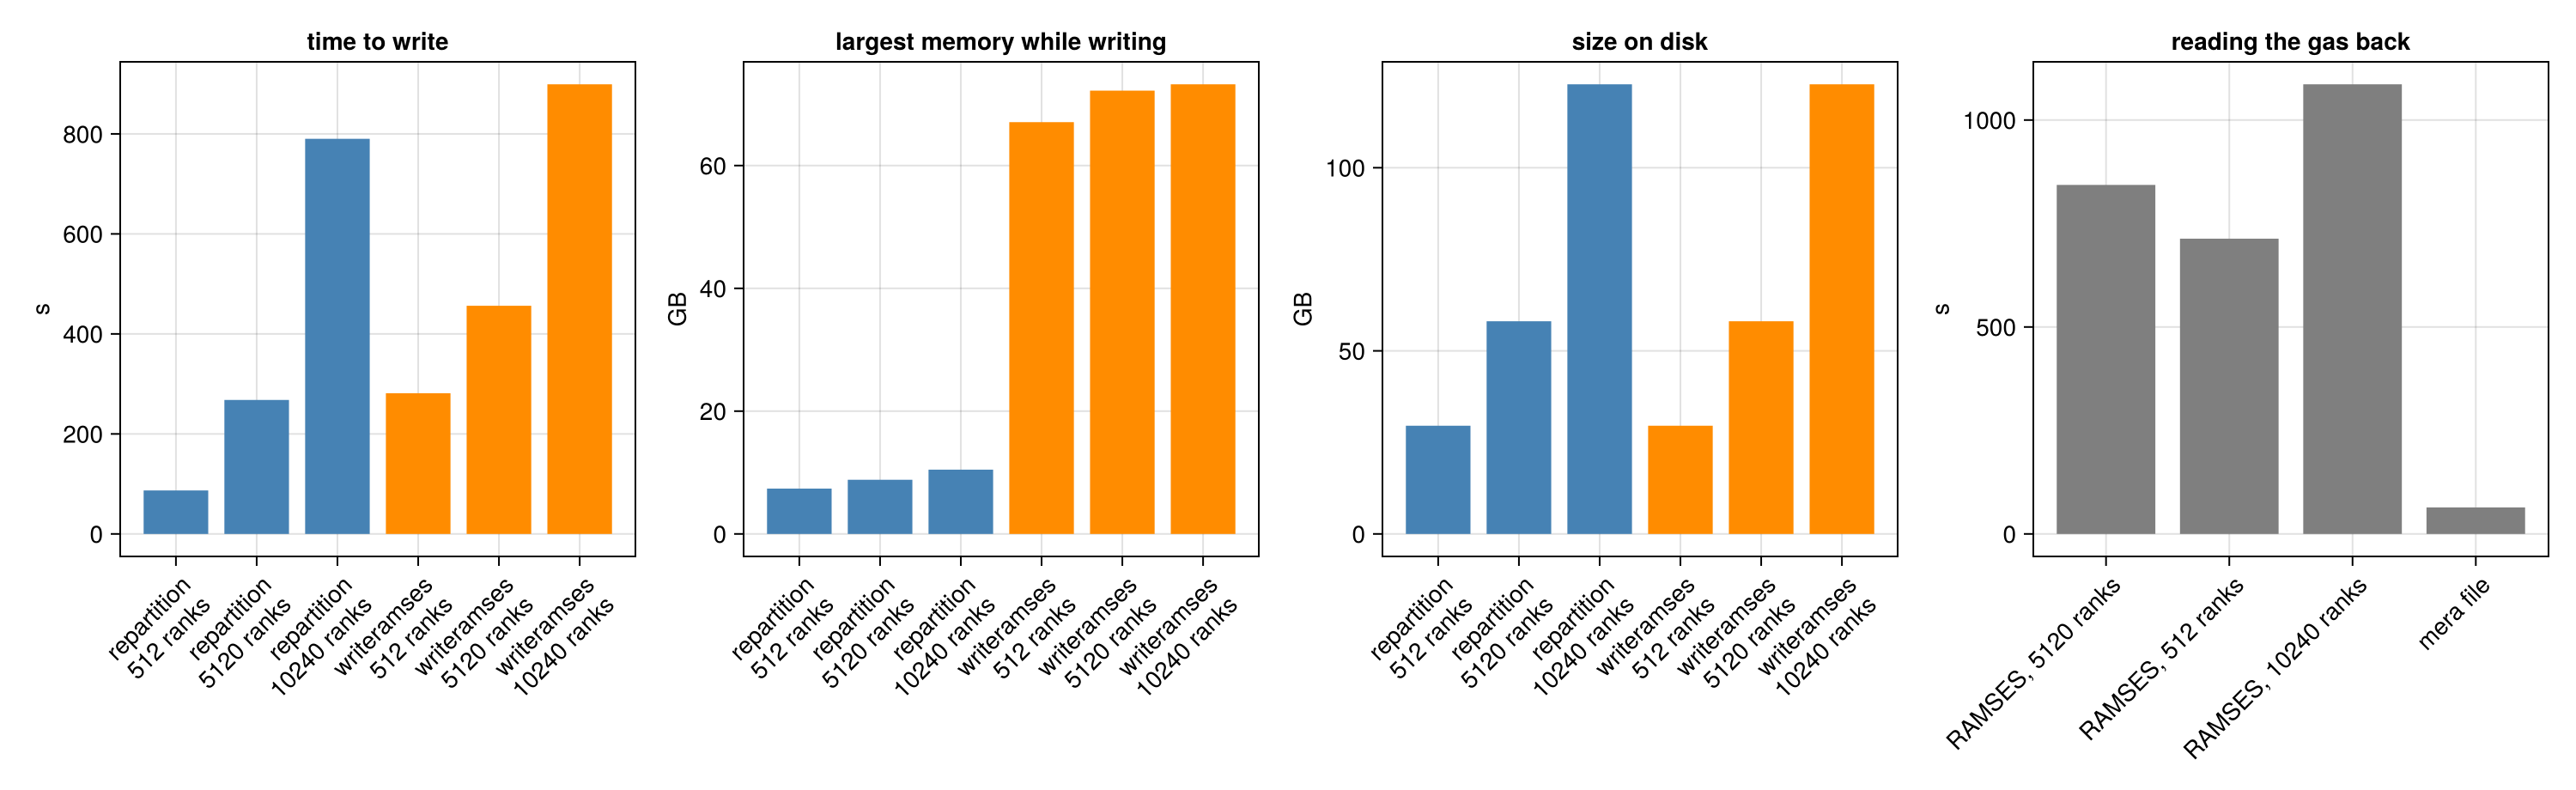

In [12]:
fig = Figure(size=(1500, 460))
w = [r for r in results if r.route != "load mera file"]
labs = ["$(r.route)\n$(r.ranks) ranks" for r in w]
for (k, (key, title, unit)) in enumerate([(:seconds, "time to write", "s"), (:peak_gb, "largest memory while writing", "GB"),
                                          (:size_gb, "size on disk", "GB")])
    ax = Axis(fig[1, k]; title, ylabel=unit, xticks=(1:length(w), labs), xticklabelrotation=π/4)
    barplot!(ax, 1:length(w), [getproperty(r, key) for r in w]; color=[r.route == "repartition" ? :steelblue : :darkorange for r in w])
end
ax = Axis(fig[1, 4]; title="reading the gas back", ylabel="s", xticks=(1:length(reads), first.(split.([r.source for r in reads], " ("))),
          xticklabelrotation=π/4)
barplot!(ax, 1:length(reads), [r.seconds for r in reads]; color=:gray50)
save(joinpath(@__DIR__, "media", "cost.png"), fig)
# every number, for reuse
open(joinpath(@__DIR__, "media", "results.csv"), "w") do io
    println(io, "route,ranks,seconds,peak_gb,size_gb,files,ngridmax")
    foreach(r -> println(io, join((r.route, r.ranks, round(r.seconds, digits=1), round(r.peak_gb, digits=2),
                                   round(r.size_gb, digits=2), r.files, r.ngridmax), ',')), results)
end
open(joinpath(@__DIR__, "media", "compare.csv"), "w") do io
    println(io, "route,ranks,same_tree,hydro,grav,particles")
    foreach(c -> println(io, join((c.route, c.ranks, c.same_tree, c.hydro, c.grav, c.particles), ',')), cmp)
end
open(joinpath(@__DIR__, "media", "reads.csv"), "w") do io
    println(io, "source,seconds,peak_gb,size_gb")
    foreach(r -> println(io, join((r.source, round(r.seconds, digits=1), round(r.peak_gb, digits=2), round(r.size_gb, digits=2)), ',')), reads)
end
fig

## The same thing, short

In [13]:
# from the RAMSES files
r = repartition(OUTPUT, SIM, 512; outpath=joinpath(WORK, "short_rep"), overwrite=true)

# from a mera file
L = (hydro     = loaddata(OUTPUT, MERAFILES, :hydro),
     gravity   = loaddata(OUTPUT, MERAFILES, :gravity),
     particles = loaddata(OUTPUT, MERAFILES, :particles))
w = writeramses(512; L..., outpath=joinpath(WORK, "short_mera"), overwrite=true)

compareramses(OUTPUT, SIM, joinpath(WORK, "short_mera"))   # every cell and particle
# for the restart namelist: ngridmax ≥ w.ngridmax_needed, npartmax ≥ w.npart_max

[1/5] reading the octree of output_00201


  reading amr file 64 / 5120


  reading amr file 512 / 5120


  reading amr file 1024 / 5120


  reading amr file 1536 / 5120


...

[3/5] hilbert decomposition and local octrees for 512 ranks


[4/5] writing amr / hydro / grav files


[5/5] particles, sinks and text files


RAMSES output repartitioned: ncpu 0 → 512
  from : leaf data (/data1/mabe/Simulations/MilkyWay/RAMSESFiles/heikou/L13_SN5_CD_null/output_00201)
  to   : /data1/mabe/Simulations/MilkyWay/RAMSESFiles/heikou/rewrite_tests_201/short_mera/output_00201
  own grids per rank      : min 54520, max 55102
  grids in memory per rank: min 64393, max 82163  (own + ghost + boundary)
  particles per rank      : min 0, max 4618
  restart namelist needs  : ngridmax ≥ 82164, npartmax ≥ 4618
  random numbers          : re-seeded by RAMSES; star formation, feedback and MC tracers follow other random draws than an uninterrupted run
  2057 files written in 186.7 s
amr header from: mera


same octree: true  (grids: 28158075 vs 28158075)
  grav max |a-b| / max|a| per variable: 0.00e+00, 0.00e+00, 0.00e+00, 0.00e+00
  hydro max |a-b| / max|a| per variable: 1.27e-19, 1.23e-16, 1.30e-16, 1.34e-16, 3.09e-16, 6.14e-17, 0.00e+00
  particles: 410342 vs 410342  families [2 => 410342] vs [2 => 410342]
  410342 DM/star particles: same identities, max |Δx|/boxlen = 0.0e+00, max |Δv|/max|v| = 0.0e+00

## The thumbnail

In [14]:
# the card shows the same galaxy split for the fewest and the most ranks, side by side
fig = Figure(size=(1100, 560))
for (k, (title, img)) in enumerate(maps[[2, end]])
    ax = Axis(fig[1, k]; title, aspect=DataAspect()); hidedecorations!(ax)
    heatmap!(ax, shuffle_colors(img); colormap=:hsv)
end
save(joinpath(@__DIR__, "media", "domains_two.png"), fig)
makethumb(joinpath(@__DIR__, "media", "domains_two.png"), joinpath(@__DIR__, "media", "ramses_any_rank_count_thumb.png"))

"/home/mabe/julia/gallery/005_ramses_any_rank_count/media/ramses_any_rank_count_thumb.png"

## Making it yours

- **Other rank counts**: any number works; the restart namelist needs `ngridmax` and `npartmax` from
  the report (`ngridmax_needed`, `npart_max`).
- **Bisection ordering** (`ordering=:bisection`) or **IO groups** (`iogroupsize=…`) for runs that use
  them; the restart namelist must then name the same ordering or `IOGROUPSIZEREP`.
- **A cheap first try**: a small output, or a public test simulation from `download_testdata()`.
- **The restart itself** was not run here (no RAMSES build on this machine). The documentation page
  restarts RAMSES from converted files for every kind of run and shows that it continues to round-off.
- **Clean up**: the rewritten outputs need several hundred GB; `rm(WORK; recursive=true)` when done.

If you build something with this, a link in
[Discussions](https://github.com/ManuelBehrendt/Mera.jl/discussions) is welcome.